# Timeseries — Peramalan ML (fitur lag + model tabular)
**Kapan dipakai:** satu deret waktu dan model statistik kurang pas (pola tidak linear, ada
hari libur/fitur kalender). Model tabular biasa dilatih dari fitur lag.

**Langkah:** fitur = nilai lag, rata-rata bergulir, bulan → model regresi → ramalan ke depan
**rekursif**: tiap langkah memakai ramalan langkah sebelumnya sebagai lag.

**Data demo:** CO2 bulanan Mauna Loa.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/timeseries/forecasting"   # GANTI saat lomba
SERIES_CSV = f"{DATA_FOLDER}/co2_monthly.csv"

DATE_COL = "date"
VALUE_COL = "value"
FREQUENCY = "MS"            # MS = awal bulan, D = harian, h = per jam
LAGS = [1, 2, 3, 6, 12]     # nilai k langkah sebelumnya dipakai sebagai fitur
HORIZON = 36                # jumlah langkah ramalan, data uji = HORIZON titik terakhir
SEED = 42

## Baca data dan split waktu

In [3]:
table = pd.read_csv(SERIES_CSV, parse_dates=[DATE_COL], index_col=DATE_COL)
y = table[VALUE_COL].asfreq(FREQUENCY)
train = y.iloc[:-HORIZON]
test = y.iloc[-HORIZON:]
print(y.shape, "| missing:", y.isna().sum(), "| latih:", len(train), "| uji:", len(test))

(526,) | missing: 0 | latih: 490 | uji: 36


## Fitur lag, rata-rata bergulir, dan bulan
`shift(1)` dulu sebelum rolling supaya nilai hari itu sendiri tidak ikut (bocor).

In [4]:
def make_features(series):
    features = pd.DataFrame(index=series.index)
    for lag in LAGS:
        features[f"lag_{lag}"] = series.shift(lag)
    previous = series.shift(1)
    features["mean_3"] = previous.rolling(3).mean()
    features["mean_12"] = previous.rolling(12).mean()
    features["month"] = series.index.month
    return features


X_train = make_features(train).dropna()     # baris awal tanpa lag lengkap dibuang
y_train = train.loc[X_train.index]
print(X_train.shape)
X_train.tail()

(478, 8)


,lag_1,lag_2,lag_3,lag_6,lag_12,mean_3,mean_12,month
date,,,,,,,,
1998-08-01,367.600,368.750,369.140,366.200,362.46,368.496667,365.243333,8
1998-09-01,365.720,367.600,368.750,367.375,360.15,367.356667,365.515000,9
1998-10-01,363.925,365.720,367.600,368.525,360.75,365.748333,365.829583,10
1998-11-01,364.320,363.925,365.720,369.140,362.38,364.655000,366.127083,11
1998-12-01,365.550,364.320,363.925,368.750,364.25,364.598333,366.391250,12


## Ramalan rekursif (tiap langkah memakai ramalan sebelumnya)
Tanggal baru ditambah satu per satu, nilainya NaN, fitur baris terakhir dihitung, ditebak,
lalu tebakan dimasukkan sebagai nilai tanggal itu.

In [5]:
STEP = pd.tseries.frequencies.to_offset(FREQUENCY)     # jarak antar tanggal


def recursive_forecast(model, history, steps):
    values = list(history.to_numpy())
    dates = list(history.index)
    for _ in range(steps):
        dates.append(dates[-1] + STEP)
        series = pd.Series(values + [np.nan], index=dates)
        last_row = make_features(series).iloc[[-1]]
        values.append(float(model.predict(last_row)[0]))
    return np.array(values[-steps:])

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris RandomForest.
Catatan: model pohon tidak bisa meramal di atas nilai tertinggi data latih (tren naik
terpotong). Untuk tren kuat, coba Ridge.

In [6]:
model = RandomForestRegressor(n_estimators=300, random_state=SEED)
# model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
# model = LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1)
# model = ExtraTreesRegressor(n_estimators=300, random_state=SEED)
# model = HistGradientBoostingRegressor(random_state=SEED)
# model = XGBRegressor(n_estimators=300, learning_rate=0.05, random_state=SEED)
# model = CatBoostRegressor(iterations=300, verbose=0, allow_writing_files=False,
#                           random_seed=SEED)
# model = KNeighborsRegressor(n_neighbors=5)
# model = make_pipeline(StandardScaler(), SVR(C=10))

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

## Evaluasi di data uji (MAE, RMSE, MAPE)

MAE : 1.77
RMSE: 2.12
MAPE (%): 0.48


C:\Users\EYZARIM\AppData\Local\Temp\ipykernel_26388\456726342.py:8: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(test.index, predictions, label="ramalan model")


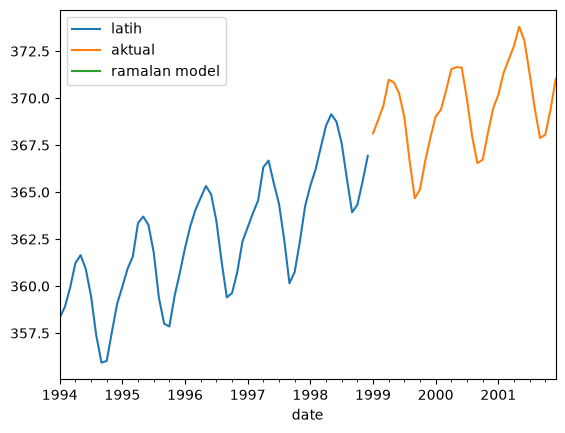

In [7]:
predictions = recursive_forecast(model, train, HORIZON)
print("MAE :", round(mean_absolute_error(test, predictions), 2))
print("RMSE:", round(root_mean_squared_error(test, predictions), 2))
print("MAPE (%):", round(100 * mean_absolute_percentage_error(test, predictions), 2))

ax = train.iloc[-60:].plot(label="latih")
test.plot(ax=ax, label="aktual")
ax.plot(test.index, predictions, label="ramalan model")
ax.legend()
plt.show()

## Latih ulang di semua data + hasil ramalan ke depan

In [8]:
X_all = make_features(y).dropna()
model.fit(X_all, y.loc[X_all.index])
future_values = recursive_forecast(model, y, HORIZON)
future_dates = pd.date_range(start=y.index[-1], periods=HORIZON + 1, freq=FREQUENCY)[1:]

result = pd.DataFrame()
result["tanggal"] = future_dates
result["ramalan"] = future_values
result.to_csv("hasil.csv", index=False)
result.head()

,tanggal,ramalan
0,2002-01-01,371.670517
1,2002-02-01,372.673733
2,2002-03-01,373.250433
3,2002-04-01,373.348350
4,2002-05-01,373.329533
